# 01 — Exploratory Data Analysis (PM2.5)


## Setup and downloaded raw dataset

In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
from IPython.display import display, Image

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if not (ROOT / 'src' / 'config.py').exists():
    raise FileNotFoundError(f"Project root not found from {Path.cwd()}; open/run inside the project.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.config import DATA_FILE, RESULTS_DIR, FIGURES_DIR, SEED, MODEL_GROUP
from src.preprocessing import load_raw, clean_target
from src.eda import exploratory_data_table, audit_tables, eda_figures
from src.timeseries import temporal_station_table, lead_lag_correlations, temporal_figures
print('Input:', DATA_FILE)
print('Project:', ROOT)


Input: C:\Users\DM PHONEIX\PycharmProjects\PythonProject\data\raw\combined_gee_pm25.csv
Project: C:\Users\DM PHONEIX\PycharmProjects\PythonProject


In [2]:
raw = load_raw()
clean, cleaning = clean_target(raw)
print("Original shape", raw.shape, "Cleaned shape", clean.shape)
display(pd.Series(cleaning, name="count").to_frame())

Original shape (41718, 15) Cleaned shape (40983, 14)


,count
rows_raw,41718
n_missing_pm25,0
n_invalid_le_zero,727
n_invalid_ge_500,8
rows_removed,735
rows_clean,40983
duplicate_exact_raw,0
duplicate_station_date_raw,0
duplicate_date_lat_lon_id_raw,0
station_count_raw,98


## Audit

In [3]:
audit = audit_tables(raw, clean, cleaning)
display(pd.Series({k:v for k,v in audit.items() if not isinstance(v, (dict,list))},name="value").to_frame())

,value
rows_raw,41718
n_missing_pm25,0
n_invalid_le_zero,727
n_invalid_ge_500,8
rows_removed,735
rows_clean,40983
duplicate_exact_raw,0
duplicate_station_date_raw,0
duplicate_date_lat_lon_id_raw,0
station_count_raw,98


## Numerical summaries and PM2.5 distribution

In [4]:
cols = ["pm25", "AOD", "NO2", "CO", "O3", "temperature_celsius", "pressure_mb", "wind_u", "wind_v"]
summary = clean[cols].describe().T
summary["skewness"] = clean[cols].skew()
summary["kurtosis"] = clean[cols].kurt()
display(summary.round(3))
print("PM2.5 > 25 (percent):", round(100*(clean.pm25>25).mean(),2))
print("PM2.5 > 50 (percent):", round(100*(clean.pm25>50).mean(),2))

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
pm25,40983.0,9.458,9.730,0.007,4.674,7.851,12.087,484.982,17.829,651.672
AOD,40983.0,0.149,0.106,0.000,0.080,0.128,0.194,5.475,7.611,246.852
NO2,38576.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000,2.123,9.178
CO,38576.0,0.032,0.004,0.013,0.029,0.031,0.034,0.098,1.398,13.768
O3,38535.0,0.144,0.014,0.104,0.134,0.140,0.151,0.229,1.151,2.278
temperature_celsius,40983.0,18.272,6.386,-1.279,12.966,18.495,23.788,34.866,-0.102,-0.971
pressure_mb,40983.0,993.817,17.180,930.317,987.986,997.729,1005.367,1033.662,-1.087,0.714
wind_u,40983.0,0.343,2.528,-11.099,-0.985,0.206,1.684,9.662,-0.178,1.034
wind_v,40983.0,-0.179,1.386,-10.860,-0.731,0.043,0.661,8.486,-1.277,4.389


PM2.5 > 25 (percent): 2.98
PM2.5 > 50 (percent): 0.29


## Missingness, station coverage and duplicates

In [5]:
display((100*clean[cols].isna().mean()).round(2).to_frame("missing_pct"))
print("Station IDs:", clean.id.nunique(),"Station names:",clean.sensor_name.nunique())
print("Duplicate (date, id):",clean.duplicated(["date","id"]).sum())
print("Distinct IDs mapped to a common name:",(clean.groupby("sensor_name").id.nunique()>1).sum())

,missing_pct
pm25,0.00
AOD,0.00
NO2,5.87
CO,5.87
O3,5.97
temperature_celsius,0.00
pressure_mb,0.00
wind_u,0.00
wind_v,0.00


Station IDs: 95 Station names: 91
Duplicate (date, id): 0
Distinct IDs mapped to a common name: 4


## Correlations, multivariate diagnostics and standardized CSV

In [6]:
ts = temporal_station_table(clean)
exploration, outlier_info = exploratory_data_table(raw, clean, cleaning, ts)
display(exploration[["variable","n_missing","pct_missing","mean","median","std","skewness","n_out_iqr","max_abs_corr","corr_partner","notes"]].head(14))
print("Multivariate outlier computation:",outlier_info)

,variable,n_missing,pct_missing,mean,median,std,skewness,n_out_iqr,max_abs_corr,corr_partner,notes
0,pm25_ugm3,0,0.000000,9.457765,7.851176,9.729713,17.829102,1613,0.159311,NO2,PM2.5 target; IF complete rows n=38535; LOF de...
1,AOD,0,0.000000,0.148693,0.128000,0.106137,7.611377,1114,0.332200,temperature_celsius,
2,NO2,2407,5.873167,0.000092,0.000086,0.000027,2.122683,2061,0.169815,latitude,Original gas unit unverified; NO forward fill
3,CO,2407,5.873167,0.031578,0.031412,0.003893,1.398186,572,0.210167,O3,Original gas unit unverified; NO forward fill
4,O3,2448,5.973208,0.143550,0.140472,0.014491,1.150540,1219,0.320234,temperature_celsius,Original gas unit unverified; NO forward fill
5,temperature_celsius,0,0.000000,18.271961,18.494734,6.386195,-0.102340,0,0.337792,wind_v,
6,pressure_mb,0,0.000000,993.817385,997.728716,17.180014,-1.086888,3179,0.198497,CO,
7,wind_u,0,0.000000,0.343444,0.205846,2.527802,-0.177789,2133,0.247343,AOD,
8,wind_v,0,0.000000,-0.178770,0.042730,1.385553,-1.276639,2234,0.337792,temperature_celsius,
9,latitude,0,0.000000,39.030362,39.448330,2.231117,0.396995,0,0.806485,longitude,"Metadata only, excluded from forecasting features"


Multivariate outlier computation: {'n_out_if': 386, 'pct_out_if': 1.001686778253536, 'n_out_lof': 150, 'pct_out_lof': 1.0, 'n_complete': 38535, 'n_lof_subset': 15000}


## Save charts and CSVs

Saved C:\Users\DM PHONEIX\PycharmProjects\PythonProject\results\Exploratory_Data.csv


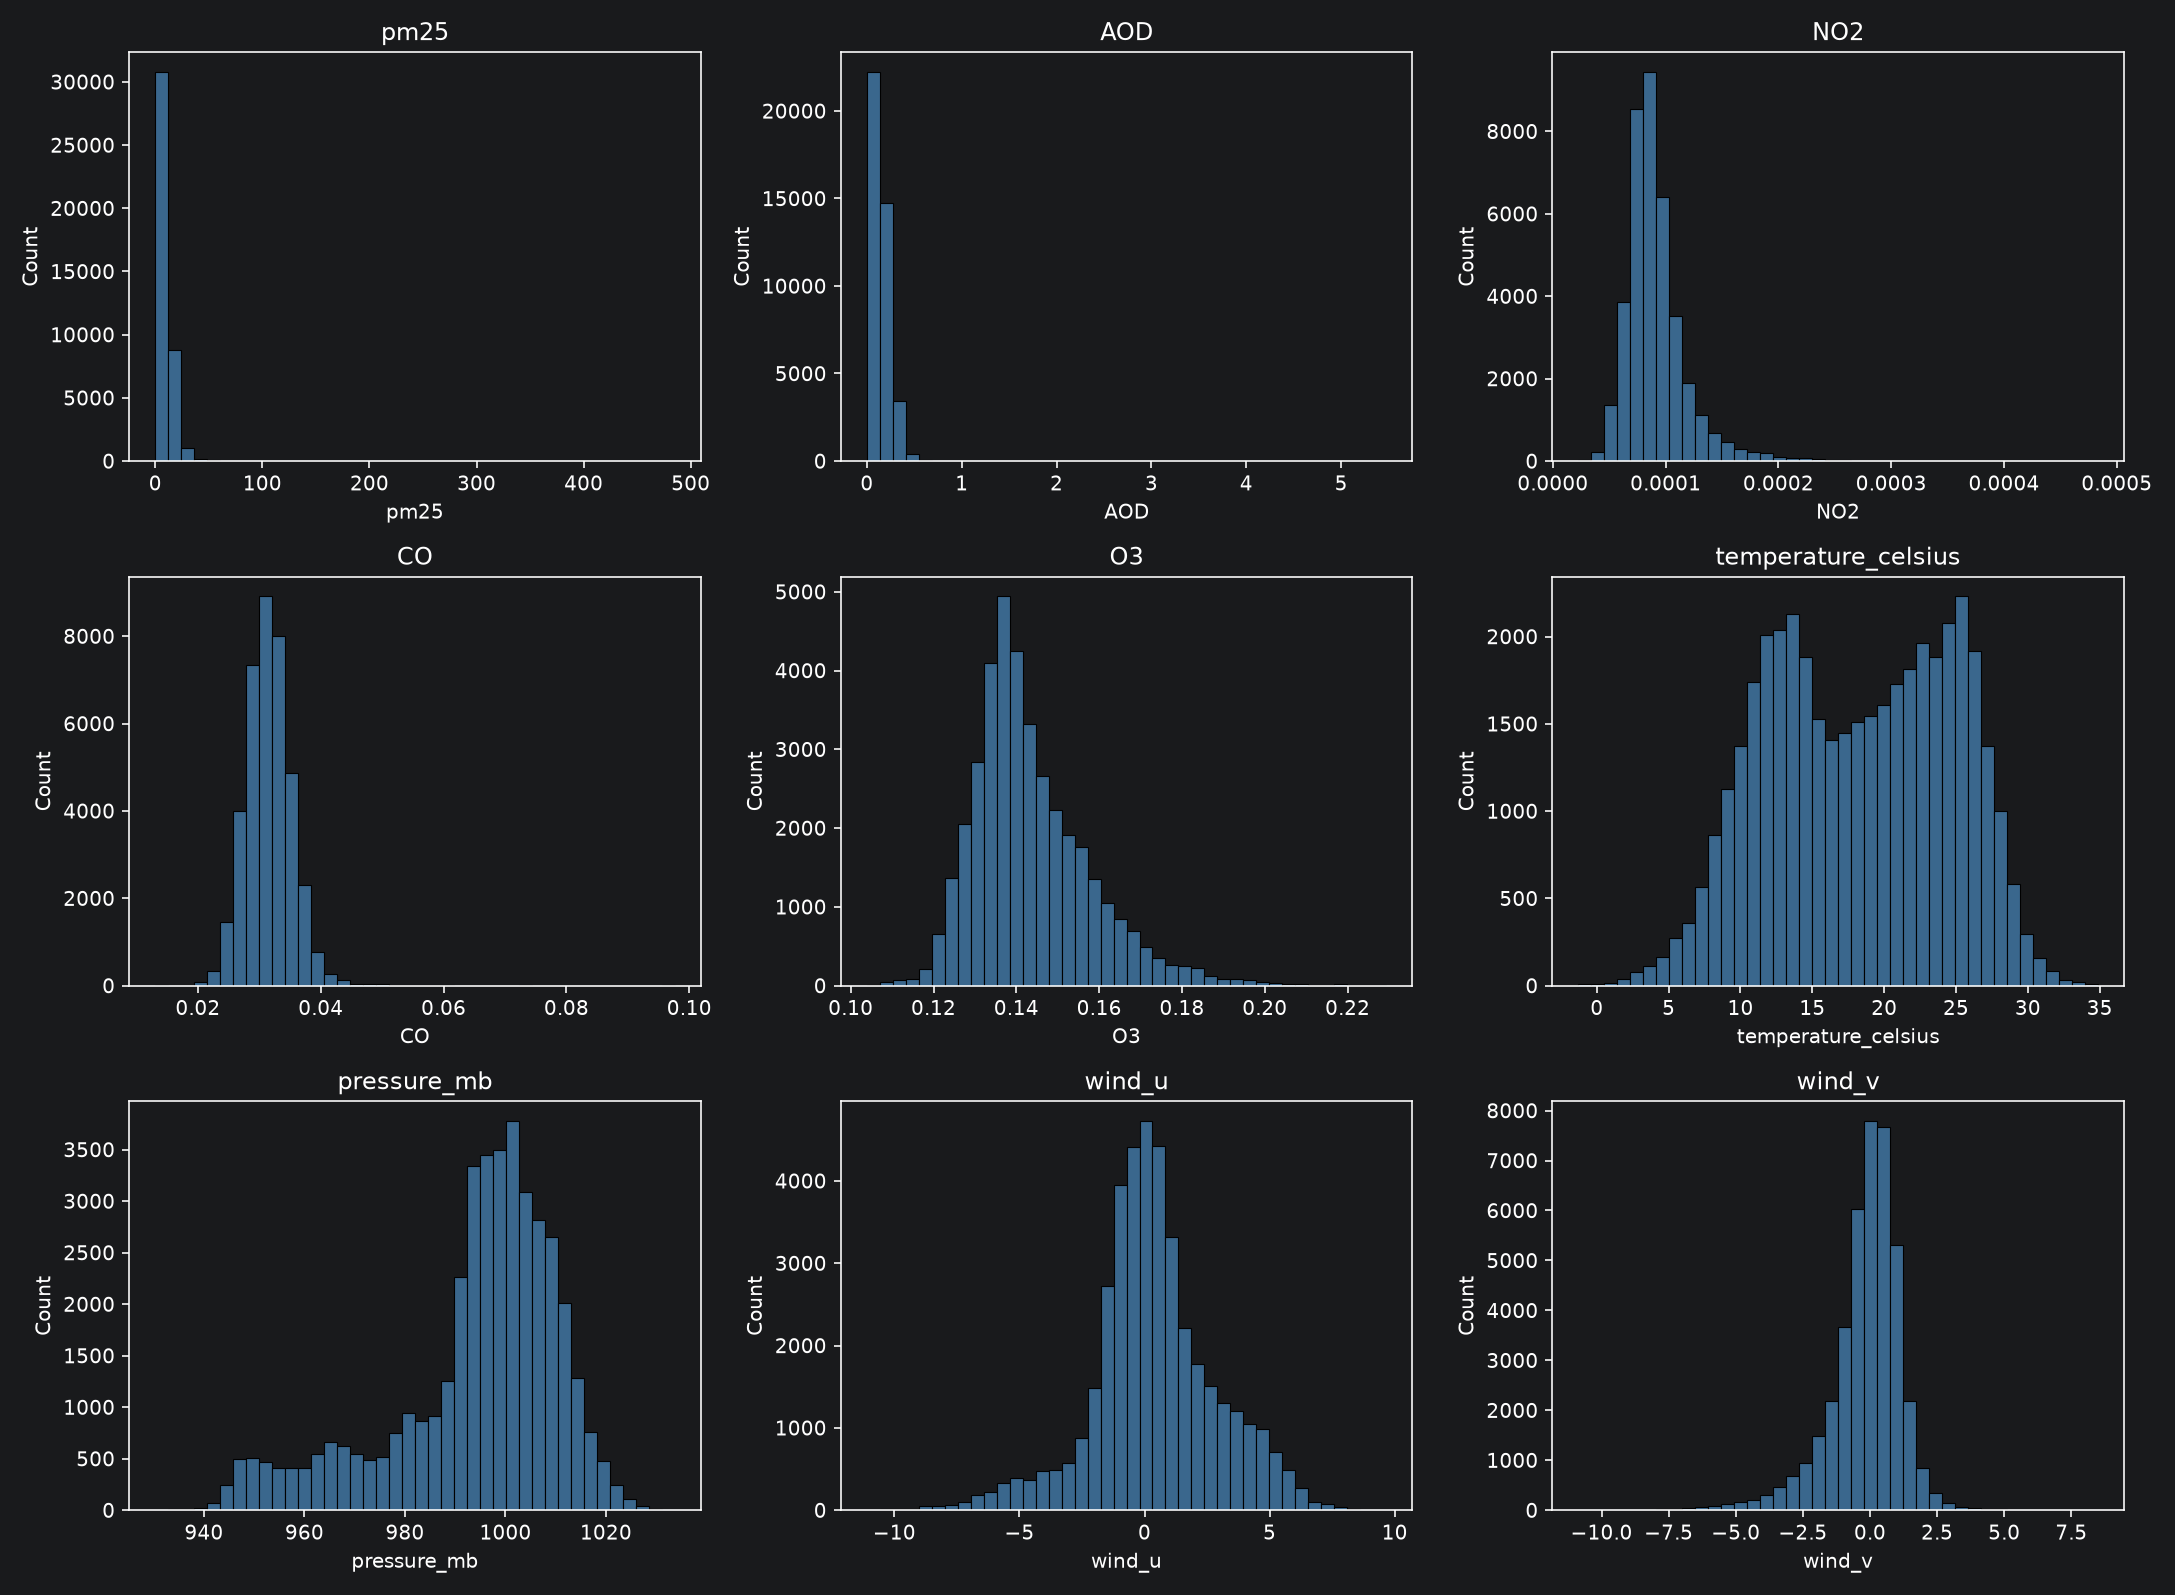

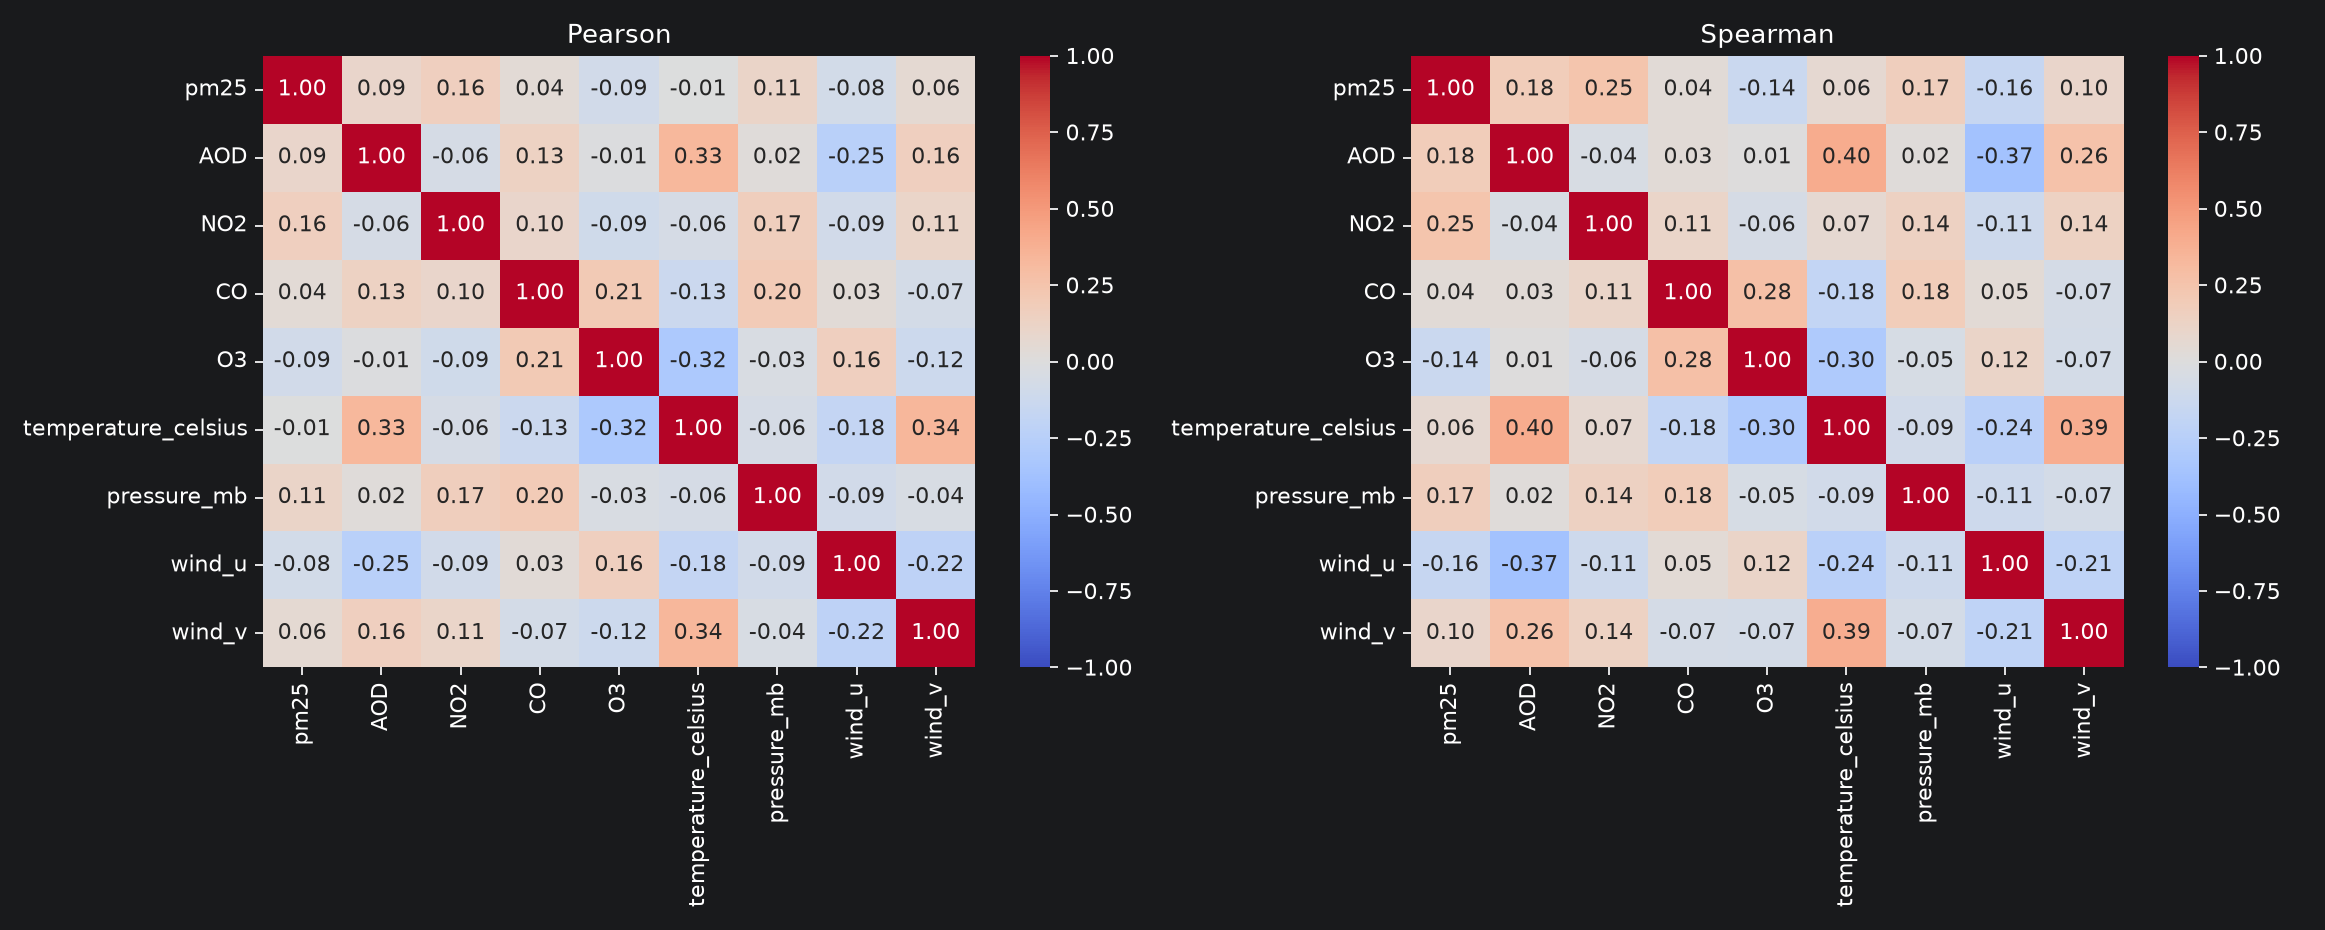

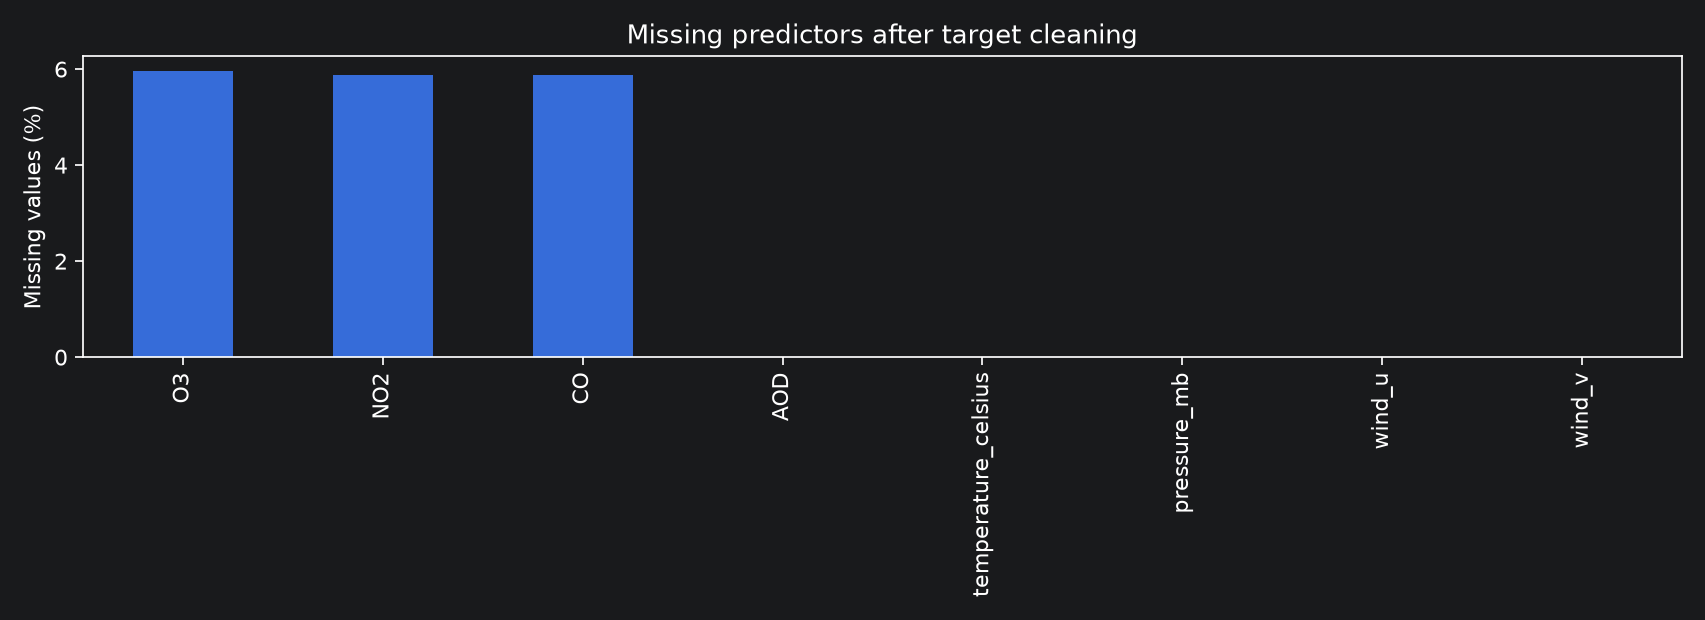

In [7]:
eda_figures(clean)
RESULTS_DIR.mkdir(parents=True,exist_ok=True)
exploration.to_csv(RESULTS_DIR/"Exploratory_Data.csv",index=False)
print("Saved", RESULTS_DIR/"Exploratory_Data.csv")
for chart in ("eda_histograms.png","correlation_matrix.png","missing_predictors.png"):
    display(Image(filename=str(FIGURES_DIR/"eda"/chart),width=700))